# Žastikaulio lūžių analizės DI agentas naudojant „Gemini API“

Šiame „Google Colab“ dokumente demonstruojamas vientisas dirbtinio intelekto agentas, skirtas žastikaulio rentgenogramoms analizuoti.

Sistema gauna rentgenogramą `X`, įvertina jos turinį, nustato galimus lūžio požymius ir sugeneruoja struktūrizuotą rezultatą `y`.

Demonstruojami du užklausų tipai:

1. **Zero-shot** – agentas analizuoja naują rentgenogramą be papildomų pavyzdžių.
2. **Few-shot** – prieš naujos rentgenogramos analizę agentui pateikiami keli žinomi `(X, y)` pavyzdžiai.

Proceso etapai:

`Duomenų įkėlimas → duomenų supratimas → analizė → išvada → rezultato pateikimas`

> Sistema sukurta mokomaisiais ir tyrimo tikslais. Jos rezultatai nėra medicininė diagnozė ir turi būti patvirtinti gydytojo.

In [6]:
# Įdiegiama oficiali Google GenAI biblioteka
!pip install -q -U google-genai

# Saugiai nuskaitomas API raktas iš Colab Secrets
from google.colab import userdata
from google import genai

GEMINI_KEY = userdata.get("GEMINI_KEY")

if not GEMINI_KEY:
    raise ValueError("Colab Secrets saugykloje nerastas GEMINI_KEY.")

# Sukuriamas Gemini API klientas
client = genai.Client(api_key=GEMINI_KEY)

print("✅ Gemini API klientas sėkmingai paruoštas.")
print("🔒 API raktas nuskaitytas saugiai ir kode nerodomas.")

✅ Gemini API klientas sėkmingai paruoštas.
🔒 API raktas nuskaitytas saugiai ir kode nerodomas.


## 1. „Gemini API“ ryšio patikrinimas

Šiame etape patikrinama, ar API raktas nuskaitytas teisingai ir ar „Gemini“ modelis gali priimti bei įvykdyti užklausą.

In [5]:
test_response = client.models.generate_content(
    model="gemini-3.8-flash",
    contents="Atsakyk tik vienu sakiniu: Gemini API ryšys veikia."
)

print("Gemini atsakymas:")
print(test_response.text)

Gemini atsakymas:
Gemini API ryšys veikia.


## 2. Ankstesnių promptų ir įvesties duomenų importavimas

Šiame etape iš GitHub saugyklos importuojami ankstesnėje 1.4 laboratorinėje užduotyje sukurti „zero-shot“ ir „few-shot“ promptai bei rentgenogramos paveikslėliai

In [8]:
# Atsisiunčiama projekto GitHub saugykla
!git clone -q https://github.com/TomashTom/humerus-fracture-classification.git

from pathlib import Path

PROMPTS_DIR = Path(
    "/content/humerus-fracture-classification/1.4/prompts"
)

if not PROMPTS_DIR.exists():
    raise FileNotFoundError(
        f"Nerastas promptų katalogas: {PROMPTS_DIR}"
    )

print("✅ Promptų katalogas rastas.")
print("\nImportuoti failai:")

for file_path in sorted(PROMPTS_DIR.iterdir()):
    print(f" - {file_path.name}")

✅ Promptų katalogas rastas.

Importuoti failai:
 - README.md
 - prompt_1_zero_shot.md
 - prompt_2_few_shot.md
 - zero_shot_input.png
 - zero_shot_output.png


## 3. Įvesties duomenų X pateikimas

Agentui pateikiama nauja žastikaulio rentgenograma `X`. Šis vaizdas bus analizuojamas naudojant „Gemini“ modelį. Sistema įvertins vaizdo turinį ir sugeneruos rezultatą `y`.

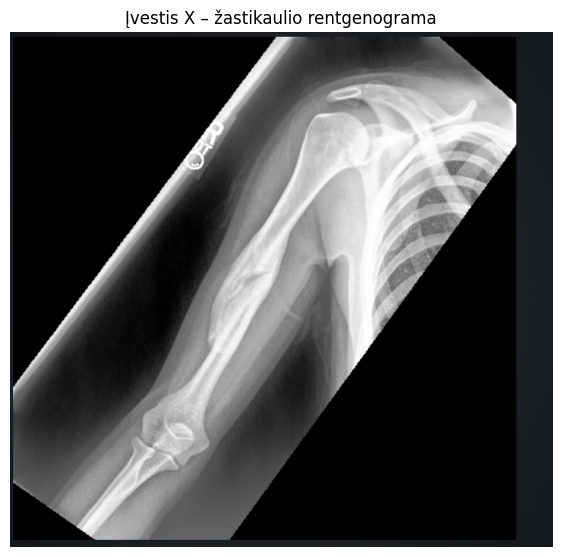

✅ Įvesties vaizdas X sėkmingai įkeltas.


In [9]:
from PIL import Image
import matplotlib.pyplot as plt

# Nurodomas įvesties rentgenogramos kelias
input_image_path = PROMPTS_DIR / "zero_shot_input.png"

# Įkeliamas vaizdas
X = Image.open(input_image_path).convert("RGB")

# Parodoma įvestis X
plt.figure(figsize=(7, 7))
plt.imshow(X)
plt.axis("off")
plt.title("Įvestis X – žastikaulio rentgenograma")
plt.show()

print("✅ Įvesties vaizdas X sėkmingai įkeltas.")

## 4. Zero-shot užklausos vykdymas

Šiame etape „Gemini“ agentui pateikiama viena nauja rentgenograma `X` ir analizės instrukcija. Papildomi teisingų atsakymų pavyzdžiai nepateikiami. Agentas turi suprasti duomenis, atlikti analizę ir sugeneruoti struktūrizuotą rezultatą `y`.

Rodomi tarpiniai proceso etapai yra trumpa veiksmų suvestinė, o ne vidinis modelio samprotavimo procesas.

In [10]:
import json
import time
from google.genai import errors, types

zero_shot_prompt = """
Tu esi mokomasis dirbtinio intelekto agentas, analizuojantis
žastikaulio rentgenogramas.

Atlik šiuos etapus:
1. Įvertink vaizdo kokybę ir matomą anatominę sritį.
2. Nustatyk, ar matomi galimo žastikaulio lūžio požymiai.
3. Jeigu įmanoma, nurodyk lūžio sritį:
   proximal, shaft, distal arba unknown.
4. Pateik trumpą sprendimo paaiškinimą.
5. Sugeneruok galutinį rezultatą y.

Atsakyk tik JSON formatu:

{
  "duomenu_supratimas": {
    "vaizdo_tipas": "rentgenograma",
    "vaizdo_kokybe": "tinkama, ribota arba netinkama"
  },
  "inference": {
    "galimas_luzis": true,
    "luzio_sritis": "proximal, shaft, distal arba unknown",
    "pasitikejimas": "žemas, vidutinis arba aukštas"
  },
  "trumpas_paaiskinimas": "trumpai nurodyk matomus požymius",
  "y": {
    "klase": 0,
    "reiksme": "lūžio nėra arba galimas lūžis"
  },
  "perspejimas": "Rezultatas skirtas tik mokymosi ir tyrimo tikslams, o ne medicininei diagnozei."
}

Klasė 0 reiškia, kad lūžio požymių nenustatyta.
Klasė 1 reiškia, kad matomi galimo lūžio požymiai.
Neišgalvok koordinačių ir nepateik galutinės medicininės diagnozės.
"""

print("1 etapas – įvestis X gauta.")
print("2 etapas – atliekamas duomenų supratimas ir analizė.")
print("3 etapas – vykdoma inferencija.")

# Pakartojimas, jeigu modelis laikinai perkrautas
for bandymas in range(5):
    try:
        zero_response = client.models.generate_content(
            model="gemini-3.8-flash",
            contents=[zero_shot_prompt, X],
            config=types.GenerateContentConfig(
                response_mime_type="application/json",
                temperature=0.2
            )
        )
        break
    except errors.ServerError:
        if bandymas == 4:
            raise
        print("Modelis laikinai užimtas. Kartojama užklausa...")
        time.sleep(5)

zero_shot_y = json.loads(zero_response.text)

print("4 etapas – sugeneruotas rezultatas y.")
print("\nZERO-SHOT REZULTATAS y:\n")
print(json.dumps(zero_shot_y, ensure_ascii=False, indent=2))

1 etapas – įvestis X gauta.
2 etapas – atliekamas duomenų supratimas ir analizė.
3 etapas – vykdoma inferencija.
4 etapas – sugeneruotas rezultatas y.

ZERO-SHOT REZULTATAS y:

{
  "duomenu_supratimas": {
    "vaizdo_tipas": "rentgenograma",
    "vaizdo_kokybe": "tinkama"
  },
  "inference": {
    "galimas_luzis": true,
    "luzio_sritis": "shaft",
    "pasitikejimas": "aukštas"
  },
  "trumpas_paaiskinimas": "Matoma žastikaulio kūno (diafizės) kortikalinio vientisumo pažaida su lūžio linija, fragmentų poslinkiu bei kaulinio rando (kalo) formavimusi.",
  "y": {
    "klase": 1,
    "reiksme": "galimas lūžis"
  },
  "perspejimas": "Rezultatas skirtas tik mokymosi ir tyrimo tikslams, o ne medicininei diagnozei."
}


## 5. Few-shot užklausos vykdymas

Few-shot metodo metu agentui pateikiami keli žinomi `(X, y)` pavyzdžiai. Jie paaiškina naudojamas klases ir galimas anatomines lūžio sritis. Po šių pavyzdžių agentas analizuoja naują įvestį `X` ir sugeneruoja rezultatą `y`.

Šiame demonstraciniame pavyzdyje naudojama ta pati rentgenograma, kad būtų galima palyginti zero-shot ir few-shot rezultatus.

In [11]:
few_shot_prompt = """
Tu esi mokomasis dirbtinio intelekto agentas, analizuojantis
žastikaulio rentgenogramas.

Žinomi (X, y) pavyzdžiai:

1 pavyzdys:
X = žastikaulio rentgenograma be matomų lūžio požymių.
y = {"klase": 0, "reiksme": "lūžio nėra", "luzio_sritis": "unknown"}

2 pavyzdys:
X = rentgenograma su lūžio požymiais žastikaulio proksimalinėje dalyje.
y = {"klase": 1, "reiksme": "galimas lūžis", "luzio_sritis": "proximal"}

3 pavyzdys:
X = rentgenograma su lūžio požymiais žastikaulio diafizėje.
y = {"klase": 1, "reiksme": "galimas lūžis", "luzio_sritis": "shaft"}

Dabar išanalizuok pateiktą naują rentgenogramą X.

Atlik šiuos etapus:
1. Įvertink vaizdo kokybę ir matomą anatominę sritį.
2. Nustatyk, ar matomi galimo žastikaulio lūžio požymiai.
3. Nurodyk galimą sritį: proximal, shaft, distal arba unknown.
4. Pateik trumpą paaiškinimą.
5. Sugeneruok galutinį rezultatą y.

Atsakyk tik JSON formatu:

{
  "duomenu_supratimas": {
    "vaizdo_tipas": "rentgenograma",
    "vaizdo_kokybe": "tinkama, ribota arba netinkama"
  },
  "inference": {
    "galimas_luzis": true,
    "luzio_sritis": "proximal, shaft, distal arba unknown",
    "pasitikejimas": "žemas, vidutinis arba aukštas"
  },
  "trumpas_paaiskinimas": "trumpai nurodyk matomus požymius",
  "y": {
    "klase": 0,
    "reiksme": "lūžio nėra arba galimas lūžis"
  },
  "perspejimas": "Rezultatas skirtas tik mokymosi ir tyrimo tikslams, o ne medicininei diagnozei."
}

Klasė 0 reiškia, kad lūžio požymių nenustatyta.
Klasė 1 reiškia, kad matomi galimo lūžio požymiai.
Neišgalvok koordinačių ir nepateik galutinės medicininės diagnozės.
"""

print("1 etapas – pateikti žinomi (X, y) pavyzdžiai.")
print("2 etapas – gauta nauja įvestis X.")
print("3 etapas – atliekama duomenų analizė ir inferencija.")

for bandymas in range(5):
    try:
        few_response = client.models.generate_content(
            model="gemini-3.8-flash",
            contents=[few_shot_prompt, X],
            config=types.GenerateContentConfig(
                response_mime_type="application/json",
                temperature=0.2
            )
        )
        break
    except errors.ServerError:
        if bandymas == 4:
            raise
        print("Modelis laikinai užimtas. Kartojama užklausa...")
        time.sleep(5)

few_shot_y = json.loads(few_response.text)

print("4 etapas – sugeneruotas rezultatas y.")
print("\nFEW-SHOT REZULTATAS y:\n")
print(json.dumps(few_shot_y, ensure_ascii=False, indent=2))

1 etapas – pateikti žinomi (X, y) pavyzdžiai.
2 etapas – gauta nauja įvestis X.
3 etapas – atliekama duomenų analizė ir inferencija.
4 etapas – sugeneruotas rezultatas y.

FEW-SHOT REZULTATAS y:

{
  "duomenu_supratimas": {
    "vaizdo_tipas": "rentgenograma",
    "vaizdo_kokybe": "tinkama"
  },
  "inference": {
    "galimas_luzis": true,
    "luzio_sritis": "shaft",
    "pasitikejimas": "aukštas"
  },
  "trumpas_paaiskinimas": "Matomas žastikaulio diafizės (kūno) lūžis su žievinio sluoksnio vientisumo sutrikimu ir fragmentų poslinkiu bei gijimo/kaulinio rando požymiais.",
  "y": {
    "klase": 1,
    "reiksme": "galimas lūžis"
  },
  "perspejimas": "Rezultatas skirtas tik mokymosi ir tyrimo tikslams, o ne medicininei diagnozei."
}


## 6. Zero-shot ir few-shot rezultatų palyginimas

Šiame etape palyginami abiejų užklausų sugeneruoti rezultatai. Tai leidžia patikrinti, ar žinomų `(X, y)` pavyzdžių pateikimas pakeitė agento išvadą.

ZERO-SHOT IR FEW-SHOT PALYGINIMAS:


,Metodas,Klasė y,Rezultatas,Lūžio sritis,Pasitikėjimas
0,Zero-shot,1,galimas lūžis,shaft,aukštas
1,Few-shot,1,galimas lūžis,shaft,aukštas


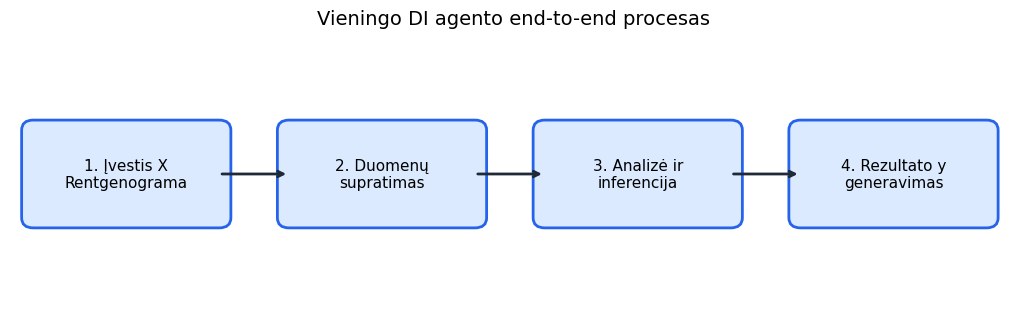

✅ Abu metodai nustatė galimą žastikaulio diafizės lūžį.


In [12]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# Sukuriama rezultatų palyginimo lentelė
comparison = pd.DataFrame([
    {
        "Metodas": "Zero-shot",
        "Klasė y": zero_shot_y["y"]["klase"],
        "Rezultatas": zero_shot_y["y"]["reiksme"],
        "Lūžio sritis": zero_shot_y["inference"]["luzio_sritis"],
        "Pasitikėjimas": zero_shot_y["inference"]["pasitikejimas"]
    },
    {
        "Metodas": "Few-shot",
        "Klasė y": few_shot_y["y"]["klase"],
        "Rezultatas": few_shot_y["y"]["reiksme"],
        "Lūžio sritis": few_shot_y["inference"]["luzio_sritis"],
        "Pasitikėjimas": few_shot_y["inference"]["pasitikejimas"]
    }
])

print("ZERO-SHOT IR FEW-SHOT PALYGINIMAS:")
display(comparison)

# Vizualizuojamas end-to-end procesas
stages = [
    "1. Įvestis X\nRentgenograma",
    "2. Duomenų\nsupratimas",
    "3. Analizė ir\ninferencija",
    "4. Rezultato y\ngeneravimas"
]

fig, ax = plt.subplots(figsize=(13, 3.5))
ax.set_xlim(0, 13)
ax.set_ylim(0, 4)
ax.axis("off")

positions = [0.3, 3.6, 6.9, 10.2]

for i, (stage, x_pos) in enumerate(zip(stages, positions)):
    box = FancyBboxPatch(
        (x_pos, 1.25),
        2.4,
        1.3,
        boxstyle="round,pad=0.15",
        facecolor="#dbeafe",
        edgecolor="#2563eb",
        linewidth=2
    )
    ax.add_patch(box)
    ax.text(
        x_pos + 1.2,
        1.9,
        stage,
        ha="center",
        va="center",
        fontsize=11
    )

    if i < len(stages) - 1:
        ax.annotate(
            "",
            xy=(positions[i + 1], 1.9),
            xytext=(x_pos + 2.4, 1.9),
            arrowprops=dict(arrowstyle="->", lw=2, color="#1f2937")
        )

plt.title("Vieningo DI agento end-to-end procesas", fontsize=14)
plt.show()

print("✅ Abu metodai nustatė galimą žastikaulio diafizės lūžį.")

### End-to-end proceso etapų paaiškinimas

1. **Įvestis:** sistema gauna žastikaulio rentgenogramą `X`.
2. **Duomenų supratimas:** nustatomas vaizdo tipas, kokybė ir matoma anatominė sritis.
3. **Reasoning:** agentas pateikia trumpą sprendimą pagrindžiančių vaizdo požymių suvestinę, neatskleisdamas vidinio samprotavimo proceso.
4. **Inferencija:** nustatoma galima lūžio klasė, anatominė sritis ir pasitikėjimo lygis.
5. **Rezultato generavimas:** pateikiamas struktūrizuotas JSON rezultatas `y` ir saugumo perspėjimas.

## 7. Refleksija

Sukurta sistema veikia kaip vientisas dirbtinio intelekto agentas, analizuojantis žastikaulio rentgenogramą. Sistema gauna įvestį `X`, supranta pateiktus duomenis, atlieka vaizdo analizę ir sugeneruoja struktūrizuotą rezultatą `y`. „Gemini API“ buvo naudojama rentgenogramos požymiams įvertinti ir galimai lūžio sričiai nustatyti. Zero-shot užklausoje agentui buvo pateikta tik nauja rentgenograma ir analizės instrukcija. Few-shot užklausoje papildomai pateikti keli žinomi `(X, y)` pavyzdžiai. Abu metodai nustatė galimą žastikaulio diafizės lūžį ir pateikė aukštą pasitikėjimą. Gerai veikė vaizdo analizė, JSON formato rezultato generavimas ir saugus API rakto naudojimas. Ateityje sistemą būtų galima patobulinti integruojant mano apmokytus „DenseNet161“, „YOLOv8“ ir „Faster R-CNN“ modelius bei rezultatų patvirtinimą pagal gydytojų anotacijas. Sistemos rezultatai skirti tik mokymosi ir tyrimo tikslams ir negali būti laikomi medicinine diagnoze.